# Question 2(c): Binomial Tree Pricing

## 1. Model Setup

This notebook implements the Cox–Ross–Rubinstein (CRR) and Jarrow–Rudd (JR) binomial trees for pricing a European call option.

Both methods use the same contract parameters and implied volatility as the Black–Scholes analytical benchmark in Question 2(a).

The analysis examines option prices, delta, gamma, risk-neutral probability admissibility, computational runtime, and convergence across six tree sizes.

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm
from time import perf_counter

s0 = 209.05
K = 210
r = 0.045

valuation_date = pd.Timestamp("2026-10-09")
expiration_date = pd.Timestamp("2027-01-15")
T = (expiration_date - valuation_date).days / 365

sigma = 0.497988  # Replace with full-precision Q1 call IV

N_values = [25, 50, 100, 200, 400, 800]

## 2. CRR Tree Parameters

The CRR model divides the option's remaining maturity into equal time steps. At each step, the stock price is multiplied by an upward or downward factor.

The risk-neutral up probability is derived from the no-arbitrage condition that the expected stock price grows at the risk-free rate.

The probability must lie between zero and one for the tree to be admissible.

In [7]:
N = 25

dt = T/N                    # Time step
u = np.exp(sigma*dt**0.5)   # Up factor
d = 1/u                     # Down factor
p = (np.exp(r*dt)-d)/(u-d)  # Risk-neutral up probability

print("dt:", dt)
print("u:", u)
print("d:", d)
print("p:", p)
print("Admissible:", 0 <= p <= 1)

d1 = (np.log(s0/K)+(r+0.5*sigma**2)*T)/(sigma*np.sqrt(T))
d2 = d1 - sigma*np.sqrt(T)

bs_call = s0*norm.cdf(d1)-K*np.exp(-r*T)*norm.cdf(d2)
bs_delta = norm.cdf(d1)
bs_gamma = norm.pdf(d1)/(s0*(sigma*np.sqrt(T)))

dt: 0.010739726027397261
u: 1.0529627062133537
d: 0.9497012516199959
p: 0.4917822730032096
Admissible: True


## 3. Terminal Stock Prices in the CRR Tree

The CRR tree is recombining, so an N-step tree contains N+1 distinct terminal stock prices.

Each terminal node is determined by the number of upward and downward moves. The terminal stock prices are calculated using the CRR up and down factors.

In [5]:
j = np.arange(N+1)

terminal_stock = s0*u**j*d**(N-j)

print("Shape:", terminal_stock.shape)
print("Lowest terminal price:", terminal_stock[0])
print("Highest terminal price:", terminal_stock[-1])

Shape: (26,)
Lowest terminal price: 57.534114194941665
Highest terminal price: 759.5824340308045


## 4. Terminal Call Payoff

At maturity, the European call payoff equals the positive part of the difference between the terminal stock price and the strike price.

These terminal payoffs serve as the starting values for backward induction through the binomial tree.

In [8]:
terminal_payoff = np.maximum(terminal_stock-K,0)

print("Payoff shape:", terminal_payoff.shape)
print("First five payoffs:", terminal_payoff[:5])
print("Last five payoffs:", terminal_payoff[-5:])

discount = np.exp(-r*dt)
call_values = terminal_payoff.copy()
call_values = discount*(call_values[1:]*p+call_values[:-1]*(1-p))
print("Shape after one step:", call_values.shape)


Payoff shape: (26,)
First five payoffs: [0. 0. 0. 0. 0.]
Last five payoffs: [292.6561444  347.31017855 407.906771   475.09205886 549.58243403]
Shape after one step: (25,)


## 5. CRR Call Pricing by Backward Induction

Starting from the terminal European call payoffs, the option values are recursively discounted using the risk-neutral probabilities.

At each backward step, the number of option value nodes decreases by one. After N steps, the remaining value represents the call option price at the valuation date.

## 6. CRR Delta and Gamma Estimation

The first two levels of the binomial tree are retained during backward induction.

The first-level option values are used to estimate delta, while the second-level values are used to estimate gamma through differences between adjacent delta estimates.

In [12]:
call_values = terminal_payoff.copy()

for steps in range(N):
    call_values = discount*(call_values[1:]*p+call_values[:-1]*(1-p))

    if len(call_values)==3:
        level_2 = call_values.copy()

    if len(call_values)==2:
        level_1 = call_values.copy()


crr_price = call_values[0] # Extract today's single option value
crr_delta = (level_1[1]-level_1[0])/(s0*u-s0*d)


print("CRR Call Price:", crr_price)
print("Black-Scholes Price:", bs_call)
print("Absolute Price Error:", abs(crr_price - bs_call))

print("Level 2:", level_2)
print("Level 1:", level_1)
print("Today:", call_values[0])

print("CRR Delta:", crr_delta)
print("BS Delta:", bs_delta)

CRR Call Price: 22.38328448456674
Black-Scholes Price: 22.175019659856545
Absolute Price Error: 0.20826482471019503
Level 2: [11.58572744 21.43184645 35.97058477]
Level 1: [16.41993676 28.56793036]
Today: 22.38328448456674
CRR Delta: 0.5627508302110227
BS Delta: 0.5628785217081697


## 7. CRR Gamma Estimation

Gamma is estimated using the three option values at the second level of the binomial tree. Two local delta estimates are calculated first, followed by a finite-difference approximation of the change in delta with respect to the stock price.

In [16]:
S_uu = s0*u**2
S_ud = s0*u*d
S_dd = s0*d**2

delta_up = (level_2[2]-level_2[1])/(S_uu-S_ud)
delta_down = (level_2[1]-level_2[0])/(S_ud-S_dd)

crr_gamma = (delta_up-delta_down)/((S_uu-S_dd)/2)

print("CRR Gamma:", crr_gamma)
print("BS Gamma:", bs_gamma)
print("Absolute Gamma Error:", abs(crr_gamma - bs_gamma))

CRR Gamma: 0.007372013044493044
BS Gamma: 0.007303565171922417
Absolute Gamma Error: 6.844787257062699e-05


## 8. Reusable CRR Binomial Tree Function

The CRR pricing procedure is encapsulated in a reusable function to evaluate different numbers of time steps.

For each tree, the function constructs the terminal stock prices, calculates the European call payoffs, and performs backward induction. The first and second levels are retained to estimate delta and gamma.

The function also records the risk-neutral up probability and computation time for convergence and efficiency comparisons.

In [3]:
def crr_tree(N):

    start = perf_counter()

    dt = T / N

    u = np.exp(sigma*dt**0.5)   # CRR up factor
    d = 1/u                     # CRR down factor
    p = (np.exp(r*dt)-d)/(u-d)  # Risk-neutral up probability

    if not (0 <= p <= 1):
        raise ValueError("Invalid risk-neutral probability")

    j = np.arange(N + 1)

    terminal_stock = s0*u**j*d**(N-j)  # Terminal stock prices
    call_values = np.maximum(terminal_stock-K,0)     # Terminal call payoffs

    discount = np.exp(-r * dt)

    for step in range(N):

        call_values = discount * (
            p * call_values[1:]
            + (1-p) * call_values[:-1]
        )

        if len(call_values) == 3:
            level_2 = call_values.copy()

        if len(call_values) == 2:
            level_1 = call_values.copy()

        price = call_values[0]

    delta = (level_1[1]-level_1[0])/(s0*u-s0*d)  # Use level_1

    S_uu = s0 * u**2
    S_ud = s0 * u * d
    S_dd = s0 * d**2

    delta_up =  (level_2[2]-level_2[1])/(S_uu-S_ud)
    delta_down = (level_2[1]-level_2[0])/(S_ud-S_dd)

    gamma = (delta_up-delta_down)/((S_uu-S_dd)/2)

    runtime = perf_counter() - start

    return {
        "N": N,
        "Price": price,
        "Delta": delta,
        "Gamma": gamma,
        "Probability": p,
        "Runtime (s)": runtime
    }

## 9. CRR Function Validation

The reusable CRR function is validated against the previously calculated 25-step tree. The resulting price, delta, and gamma should match the original implementation before extending the analysis to larger trees.

In [18]:
test_crr = crr_tree(25)

for key, value in test_crr.items():
    print(f"{key}: {value}")

N: 25
Price: 22.38328448456674
Delta: 0.5627508302110227
Gamma: 0.007372013044493044
Probability: 0.4917822730032096
Runtime (s): 0.0003659999929368496


### CRR Binomial Tree Convergence Analysis

The Cox–Ross–Rubinstein (CRR) binomial tree is evaluated using 25, 50, 100, 200, 400, and 800 time steps. For each tree, the risk-neutral probability is checked for admissibility, and the call price, delta, gamma, and execution time are recorded. The absolute pricing error is calculated relative to the analytical Black–Scholes benchmark to assess convergence.

In [8]:
N_values = [25, 50, 100, 200, 400, 800]

crr_results = []

for N in N_values:
    result = crr_tree(N)

    result["Price Error"] = abs(result["Price"] - bs_call)
    result["Delta Error"] = abs(result["Delta"] - bs_delta)
    result["Gamma Error"] = abs(result["Gamma"] - bs_gamma)
    result["Admissible"] = 0 <= result["Probability"] <= 1

    crr_results.append(result)

crr_df = pd.DataFrame(crr_results)

display(crr_df)

,N,Price,Delta,Gamma,Probability,Runtime (s),Price Error,Delta Error,Gamma Error,Admissible
0,25,22.383284,0.562751,0.007372,0.491782,0.000300,0.208265,0.000128,0.000068,True
1,50,22.117601,0.562641,0.007396,0.494189,0.000408,0.057419,0.000238,0.000092,True
2,100,22.155570,0.562774,0.007346,0.495890,0.000694,0.019450,0.000105,0.000042,True
3,200,22.171380,0.562835,0.007322,0.497094,0.001051,0.003639,0.000043,0.000019,True
4,400,22.177026,0.562862,0.007312,0.497945,0.002113,0.002006,0.000016,0.000008,True
5,800,22.178248,0.562874,0.007307,0.498547,0.006110,0.003229,0.000005,0.000003,True


### CRR Pricing and Greeks Convergence

The convergence of the CRR binomial tree is evaluated by plotting the absolute pricing error and the errors in delta and gamma against the number of time steps. The pricing error is not necessarily monotonic because the relative position of the strike price and terminal stock-price nodes changes with the grid resolution. The Greeks are also examined to assess the accuracy of the numerical sensitivities.

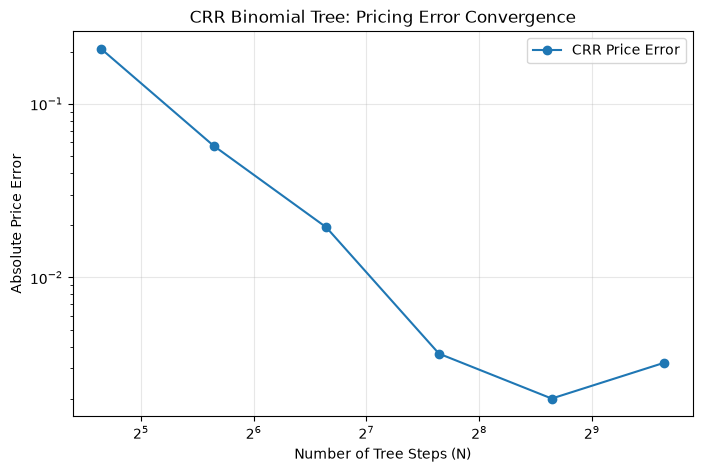

In [20]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(crr_df["N"], crr_df["Price Error"],
        marker="o", label="CRR Price Error")

ax.set_xlabel("Number of Tree Steps (N)")
ax.set_ylabel("Absolute Price Error")
ax.set_title("CRR Binomial Tree: Pricing Error Convergence")
ax.set_xscale("log", base=2)
ax.set_yscale("log")
ax.grid(True, alpha=0.3)
ax.legend()

plt.show()

### CRR Delta and Gamma Errors

The absolute errors in delta and gamma are plotted separately to compare their convergence patterns. Because the two sensitivities have different numerical scales, separate panels are used to make their trends easier to interpret.

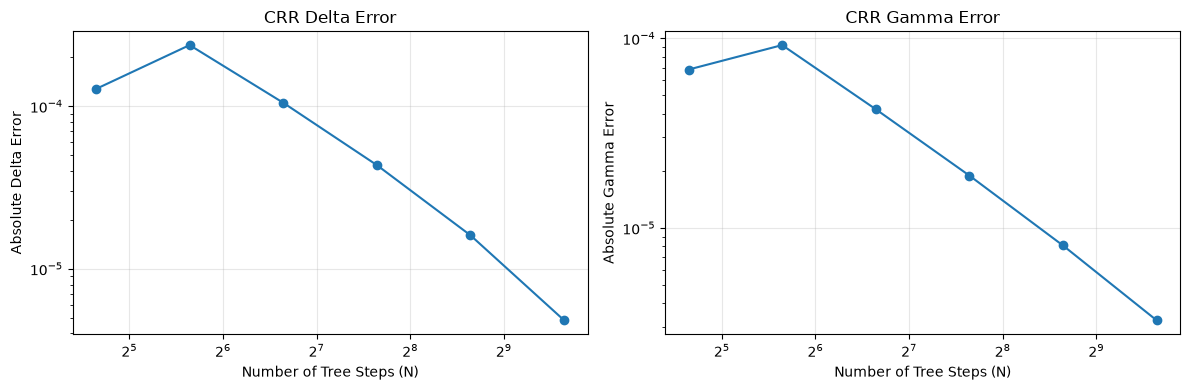

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(crr_df["N"], crr_df["Delta Error"], marker="o")
axes[0].set_title("CRR Delta Error")
axes[0].set_xlabel("Number of Tree Steps (N)")
axes[0].set_ylabel("Absolute Delta Error")

axes[1].plot(crr_df["N"], crr_df["Gamma Error"], marker="o")
axes[1].set_title("CRR Gamma Error")
axes[1].set_xlabel("Number of Tree Steps (N)")
axes[1].set_ylabel("Absolute Gamma Error")

for ax in axes:
    ax.set_xscale("log", base=2)
    ax.set_yscale("log")
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Jarrow–Rudd Binomial Tree Implementation

The Jarrow–Rudd binomial tree uses equal up and down probabilities of 0.5. Unlike the CRR construction, the risk-neutral drift is incorporated into the up and down factors. The terminal payoff, backward induction, and numerical calculations of delta and gamma follow the same procedure as the CRR tree.

In [11]:
def jr_tree(N):

    start = perf_counter()

    dt = T / N

    u = np.exp((r-0.5*sigma**2)*dt+sigma*np.sqrt(dt))   # jr up factor
    d = np.exp((r-0.5*sigma**2)*dt-sigma*np.sqrt(dt))   # jr down factor
    p = 0.5  # jr probability

    if not (0 <= p <= 1):
        raise ValueError("Invalid risk-neutral probability")

    j = np.arange(N + 1)

    terminal_stock = s0*u**j*d**(N-j)  # Terminal stock prices
    call_values = np.maximum(terminal_stock-K,0)     # Terminal call payoffs

    discount = np.exp(-r * dt)

    for step in range(N):

        call_values = discount * (
            p * call_values[1:]
            + (1-p) * call_values[:-1]
        )

        if len(call_values) == 3:
            level_2 = call_values.copy()

        if len(call_values) == 2:
            level_1 = call_values.copy()

        price = call_values[0]

    delta = (level_1[1]-level_1[0])/(s0*u-s0*d)  # Use level_1

    S_uu = s0 * u**2
    S_ud = s0 * u * d
    S_dd = s0 * d**2

    delta_up =  (level_2[2]-level_2[1])/(S_uu-S_ud)
    delta_down = (level_2[1]-level_2[0])/(S_ud-S_dd)

    gamma = (delta_up-delta_down)/((S_uu-S_dd)/2)

    runtime = perf_counter() - start

    return {
        "N": N,
        "Price": price,
        "Delta": delta,
        "Gamma": gamma,
        "Probability": p,
        "Runtime (s)": runtime
    }

### Jarrow–Rudd Tree Validation

The Jarrow–Rudd implementation is first tested using 25 time steps. The output is checked for a valid risk-neutral probability, a positive call price, and reasonable delta and gamma estimates before proceeding to the full convergence experiment.

In [24]:
test_jr = jr_tree(25)

for key, value in test_jr.items():
    print(f"{key}: {value}")

N: 25
Price: 22.272315001338924
Delta: 0.5613451749673778
Gamma: 0.007432943570284389
Probability: 0.5
Runtime (s): 0.00024860003031790257


### Jarrow–Rudd Tree Convergence Analysis

The Jarrow–Rudd tree is evaluated using the same six time-step counts as the CRR tree. The call price, delta, gamma, risk-neutral probability, and runtime are recorded. Absolute pricing and Greeks errors are calculated against the Black–Scholes benchmark to compare the convergence behavior of the two binomial constructions.

In [12]:
jr_results = []

for N in N_values:
    result = jr_tree(N)

    result["Price Error"] = abs(result["Price"] - bs_call)
    result["Delta Error"] = abs(result["Delta"] - bs_delta)
    result["Gamma Error"] = abs(result["Gamma"] - bs_gamma)
    result["Admissible"] = 0 <= result["Probability"] <= 1

    jr_results.append(result)

jr_df = pd.DataFrame(jr_results)

display(jr_df)

,N,Price,Delta,Gamma,Probability,Runtime (s),Price Error,Delta Error,Gamma Error,Admissible
0,25,22.272315,0.561345,0.007433,0.5,0.000230,0.097295,0.001533,0.000129,True
1,50,22.258695,0.562479,0.007354,0.5,0.000229,0.083676,0.000400,0.000051,True
2,100,22.225969,0.562646,0.007326,0.5,0.000433,0.050949,0.000233,0.000022,True
3,200,22.191472,0.562730,0.007318,0.5,0.000774,0.016452,0.000149,0.000014,True
4,400,22.161425,0.562772,0.007318,0.5,0.001518,0.013594,0.000107,0.000015,True
5,800,22.180961,0.562850,0.007306,0.5,0.004790,0.005942,0.000029,0.000003,True


### Comparison of CRR and Jarrow–Rudd Pricing Convergence

The absolute pricing errors of the CRR and Jarrow–Rudd trees are plotted against the number of time steps on logarithmic axes. This comparison highlights differences in finite-step accuracy and possible oscillatory or non-monotonic convergence, even though both constructions approximate the same Black–Scholes model as the number of steps increases.

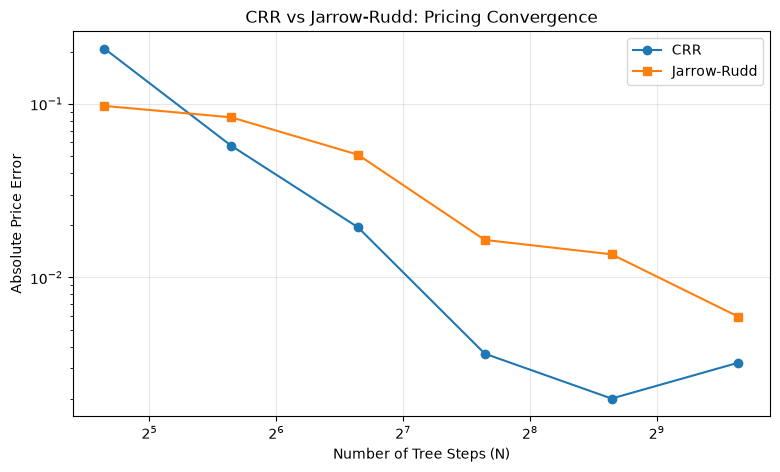

In [26]:
plt.figure(figsize=(9, 5))

plt.plot(
    crr_df["N"],
    crr_df["Price Error"],
    marker="o",
    label="CRR"
)

plt.plot(
    jr_df["N"],
    jr_df["Price Error"],
    marker="s",
    label="Jarrow-Rudd"
)

plt.xscale("log", base=2)
plt.yscale("log")

plt.xlabel("Number of Tree Steps (N)")
plt.ylabel("Absolute Price Error")
plt.title("CRR vs Jarrow-Rudd: Pricing Convergence")

plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

### CRR and Jarrow–Rudd: Greeks and Runtime Comparison

The absolute delta and gamma errors are compared with their Black–Scholes benchmarks across the six tree sizes. Computational runtimes are also compared to evaluate the trade-off between numerical accuracy and computational cost. Since individual execution times are short, runtime differences should be interpreted cautiously.

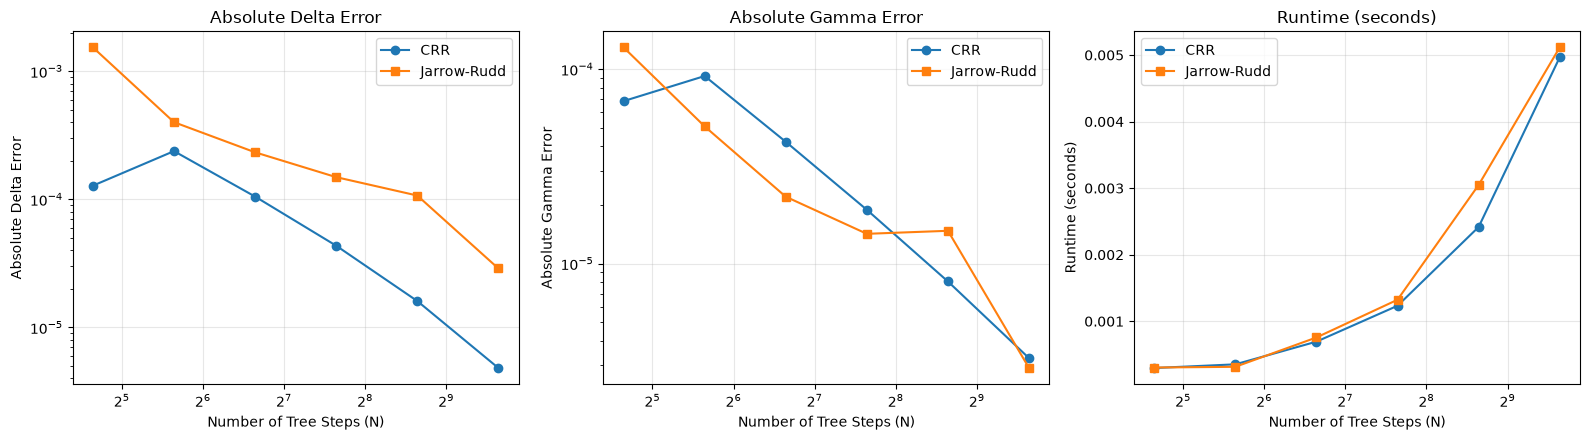

In [27]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

metrics = [
    ("Delta Error", "Absolute Delta Error"),
    ("Gamma Error", "Absolute Gamma Error"),
    ("Runtime (s)", "Runtime (seconds)")
]

for ax, (column, ylabel) in zip(axes, metrics):
    ax.plot(
        crr_df["N"], crr_df[column],
        marker="o", label="CRR"
    )
    ax.plot(
        jr_df["N"], jr_df[column],
        marker="s", label="Jarrow-Rudd"
    )

    ax.set_xscale("log", base=2)

    if column != "Runtime (s)":
        ax.set_yscale("log")

    ax.set_xlabel("Number of Tree Steps (N)")
    ax.set_ylabel(ylabel)
    ax.set_title(ylabel)
    ax.grid(True, alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

### Q2(c) — Comparison of CRR and Jarrow–Rudd Binomial Trees

Both the Cox–Ross–Rubinstein (CRR) and Jarrow–Rudd (JR) binomial trees were implemented for 25, 50, 100, 200, 400, and 800 time steps. The risk-neutral probabilities were verified to be admissible for all tested configurations. The numerical call prices, delta, gamma, and runtimes were compared against the Black–Scholes analytical benchmarks.

**Pricing accuracy and convergence.**

Both trees exhibit an overall convergence toward the Black–Scholes price as the number of time steps increases. At 800 steps, the absolute pricing errors are approximately 0.003229 for CRR and 0.005942 for JR. CRR produces a smaller pricing error in five of the six tested configurations, although JR is more accurate at 25 steps.

The convergence is not necessarily monotonic. For example, the CRR pricing error decreases from 0.003639 at 200 steps to 0.002006 at 400 steps, but increases to 0.003229 at 800 steps. This behavior can arise from the changing alignment of the discrete terminal stock-price nodes with the strike price. Because the call payoff has a kink at the strike, the discretization error may oscillate as the tree is refined.

**Delta and gamma accuracy.**

CRR produces smaller absolute delta errors across all six tested tree sizes. At 800 steps, the CRR delta error is approximately 0.000005, compared with 0.000029 for JR. Gamma errors also generally decrease as the trees are refined, although neither construction consistently dominates the other at every tree size.

These findings indicate that a model with a smaller pricing error does not necessarily produce more accurate Greeks. Numerical derivatives are sensitive to the local spacing and values of the tree nodes.

**Computational efficiency.**

The two constructions have similar computational runtimes because they use the same backward-induction structure. Their computational complexity is approximately O(N²), as each time step requires updating a decreasing number of nodes. The observed runtimes increase with tree size, reaching approximately 0.005 seconds at 800 steps for both methods. Small differences in measured runtime should not be interpreted as systematic performance advantages without repeated benchmarking.

**Why both trees converge to the same value.**

CRR and JR use different discrete specifications for the up and down factors and risk-neutral probabilities. CRR uses reciprocal up and down factors with a calibrated risk-neutral probability, while JR uses an equal probability of 0.5 and incorporates the risk-neutral drift into its movement factors.

Although these constructions differ at finite N, both approximate the same risk-neutral geometric Brownian motion as the time step approaches zero. Consequently, both converge toward the same Black–Scholes option value, while their finite-step prices and Greeks may differ.

**Conclusion.**

For the tested contract and grid sizes, CRR generally offers better pricing and delta accuracy at a computational cost similar to JR. However, neither method is uniformly superior across all metrics. Model selection should consider price accuracy, Greek estimation, convergence behavior, and computational efficiency rather than relying on pricing error alone.

In [13]:
## Export crr and jr df
crr_df.to_csv("../Data/processed/crr_results.csv", index=False)
jr_df.to_csv("../Data/processed/jrr_results.csv", index=False)